![](img/banner.png)

# N-Queen Problem

**Mahmood Amintoosi, Fall 2026**

Computer Science Dept, Ferdowsi University of Mashhad


## The problem

Place $n$ queens on an $n\times n$ chessboard so that no two attack each other.
Two queens attack if they share a row, a column, or a diagonal.

Why is this in a data-science course? Because it is the cleanest example of a
**discrete search with constraints**, and it uses exactly the recursion of the
[SAT-Table](SAT-Table.ipynb) notebook, with one addition: before recursing we
check whether the partial assignment can still be completed. That check,
**pruning**, is what makes search practical.

## Representation

Number rows and columns $0,\ldots,n-1$. Since no two queens may share a row, we
may as well put exactly one queen in every row: row $i$ gets one queen, and the
only unknown is its column. So a candidate solution is a vector

$$x=(x_0,x_1,\ldots,x_{n-1}),\qquad x_i\in\{0,\ldots,n-1\},$$

where $x_i$ is the column of the queen in row $i$. For $n=4$ the vector
`[1, 3, 0, 2]` means: column 1 in row 0, column 3 in row 1, column 0 in row 2,
column 2 in row 3 (rows counted from the top, columns from the left, both from
0).

Ignoring the "no shared column" rule there are $n^n$ vectors; with it, only the
permutations, $n!$ of them. Compare:


In [1]:
import math

print(f"{'n':>3} {'n**n':>22} {'n!':>22}")
for n in [4, 6, 8, 10, 12, 16]:
    print(f"{n:>3} {n ** n:>22} {math.factorial(n):>22}")


  n                   n**n                     n!
  4                    256                     24
  6                  46656                    720
  8               16777216                  40320
 10            10000000000                3628800
 12          8916100448256              479001600
 16   18446744073709551616         20922789888000


$8^8=16\,777\,216$ but $8!=40\,320$: the column rule alone removes $99.8\%$ of
the candidates. Checking partial boards removes almost all of the rest.

## The safety test

Suppose rows $0,\ldots,i-1$ already contain queens in columns
$x_0,\ldots,x_{i-1}$, and we want to put a queen in row $i$, column $j$. The
placement is safe if, for every earlier row $k<i$:

* **column**: $x_k \neq j$;
* **diagonal**: the two queens lie on a common diagonal exactly when the
  vertical distance equals the horizontal distance, $|x_k-j| = |k-i|$. This one
  test covers both diagonals, slopes $+1$ and $-1$.

Note what is *not* checked: the row, because row $i$ holds a single queen by
construction, and rows $k>i$, because they are still empty. Only the past
matters, which is a general principle of backtracking.


In [2]:
def is_safe(x, i, j):
    """Can the queen of row i be put in column j, given rows 0..i-1?"""
    for k in range(i):
        if x[k] == j:                        # same column
            return False
        if abs(x[k] - j) == abs(k - i):      # same diagonal
            return False
    return True


`x` may be longer than $i$; the entries $x_k$ for $k\ge i$ are never read, which
is exactly why we are allowed to fill the vector as we go.

## Backtracking

The recursive search works level by level. At level $i$ we try every column $j$;
if the placement is safe we write `x[i] = j` and recurse to level $i+1$. When we
come back, the next $j$ overwrites `x[i]`, so no "undo" is needed. (The line
`x[i] = -1` that people often add after the recursive call changes nothing:
`is_safe` never looks at `x[i]`, and the loop assigns it before the next use.)

At level $n$ every row is filled and every test has passed, so the vector is a
solution.


In [3]:
def nqueen(i, x):
    """Print all solutions whose first i rows are x[0..i-1]."""
    n = len(x)
    if i == n:                 # base case: a complete, safe placement
        print(x)
        return
    for j in range(n):
        if is_safe(x, i, j):
            x[i] = j
            nqueen(i + 1, x)


nqueen(0, [-1] * 4)


[1, 3, 0, 2]
[2, 0, 3, 1]


The two printed vectors, `[1, 3, 0, 2]` and `[2, 0, 3, 1]`, are mirror images of
each other (see the picture below). For $n=2$ and $n=3$ nothing is printed: no
solution exists.

## How much does pruning save?

Count how often the function is entered, and compare with the size of the search
space $n^n$:


In [4]:
nodes = 0


def nqueen_count(i, x):
    global nodes
    nodes += 1
    n = len(x)
    if i == n:
        return 1
    total = 0
    for j in range(n):
        if is_safe(x, i, j):
            x[i] = j
            total += nqueen_count(i + 1, x)
    return total


for n in [4, 6, 8, 10]:
    nodes = 0
    solutions = nqueen_count(0, [-1] * n)
    print(f"n = {n:>2}   solutions = {solutions:>4}   "
          f"nodes visited = {nodes:>8}   n**n = {n ** n:>12}")


n =  4   solutions =    2   nodes visited =       17   n**n =          256
n =  6   solutions =    4   nodes visited =      153   n**n =        46656
n =  8   solutions =   92   nodes visited =     2057   n**n =     16777216


n = 10   solutions =  724   nodes visited =    35539   n**n =  10000000000


With $n=8$, $8^8=16\,777\,216$ vectors exist but only a few thousand nodes are
visited. That is the power of backtracking: the constraints are used **before**
the work is done, not after.

## Counting solutions

The generators of the SAT-Table notebook make the search reusable: replace
`print` by `yield`, and the solutions can be counted, filtered or drawn.


In [5]:
def nqueen_solutions(i, x):
    n = len(x)
    if i == n:
        yield list(x)
        return
    for j in range(n):
        if is_safe(x, i, j):
            x[i] = j
            yield from nqueen_solutions(i + 1, x)


In [6]:
for n in range(1, 11):
    count = sum(1 for _ in nqueen_solutions(0, [-1] * n))
    print(f"n = {n:>2}: {count:>4} solutions")


n =  1:    1 solutions
n =  2:    0 solutions
n =  3:    0 solutions
n =  4:    2 solutions
n =  5:   10 solutions
n =  6:    4 solutions
n =  7:   40 solutions
n =  8:   92 solutions


n =  9:  352 solutions


n = 10:  724 solutions


The counts $1, 0, 0, 2, 10, 4, 40, 92, 352, 724$ are not monotone, and they are
not obvious: there are fewer solutions for $n=6$ than for $n=5$. This is a
problem one solves by search, not by a formula.

## One solution, drawn

A board can be printed as text, which also works in slides and on paper:


In [7]:
def print_board(x):
    n = len(x)
    for i in range(n):
        print(" ".join("Q" if x[i] == j else "." for j in range(n)))
    print()


print_board([1, 3, 0, 2])


. Q . .
. . . Q
Q . . .
. . Q .



or drawn as a picture (the dark squares are $(i+j)$ odd):


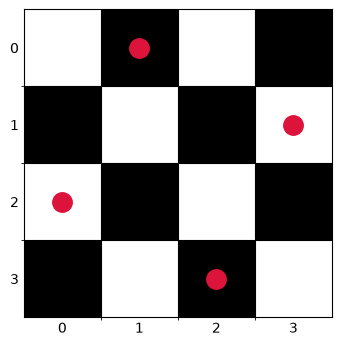

In [8]:
import matplotlib.pyplot as plt


def draw(x):
    n = len(x)
    board = [[(i + j) % 2 for j in range(n)] for i in range(n)]
    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(board, cmap="gray_r", vmin=0, vmax=1)
    ax.plot(x, range(n), "o", color="crimson", markersize=14)
    ax.set_xticks(range(n))
    ax.set_yticks(range(n))
    ax.set_xticks([c - 0.5 for c in range(1, n)], minor=True)
    ax.set_yticks([r - 0.5 for r in range(1, n)], minor=True)
    ax.grid(which="minor", color="black", linewidth=0.8)
    ax.set_xlim(-0.5, n - 0.5)
    ax.set_ylim(n - 0.5, -0.5)
    ax.tick_params(length=0)
    plt.show()


draw([1, 3, 0, 2])


## From hard constraints to a soft objective

So far a candidate is either a solution or not. Many real problems have no
candidate that satisfies everything, and then the question becomes *how badly*
a candidate violates the rules. That number is an **objective** (a cost) that we
try to minimize, and the search becomes an optimization problem.

For the queens, the natural cost of a complete assignment is the number of
attacking pairs:


In [9]:
def count_conflicts(x):
    """Number of attacking pairs of queens in a complete assignment x."""
    n = len(x)
    pairs = []
    for i in range(n):
        for j in range(i + 1, n):
            if x[i] == x[j] or abs(x[i] - x[j]) == abs(i - j):
                pairs.append((i, j))
    return len(pairs), pairs


In [10]:
conflicts, pairs = count_conflicts([1, 3, 0, 2])
print("a solution              -> conflicts:", conflicts)

conflicts, pairs = count_conflicts(list(range(8)))
print("all on the main diagonal -> conflicts:", conflicts)
print("first three attacking pairs:", pairs[:3])


a solution              -> conflicts: 0
all on the main diagonal -> conflicts: 28
first three attacking pairs: [(0, 1), (0, 2), (0, 3)]


A solution has cost 0, while the assignment with every queen on the main diagonal
has every pair attacking: $\binom{8}{2}=28$.

With a cost function we may drop the safety test altogether and use a *local*
search: start from a complete assignment and repeatedly move a queen so that the
number of conflicts decreases. It usually finds *a* solution, but it can get
stuck in a local minimum, exactly like k-means.

This is the bridge to clustering. In clustering there are no hard constraints at
all: every labeling is a legal clustering, and among the $S(n,k)$ clusterings we
look for the one of smallest cost, the within-cluster sum of squares. The search
space, the recursion that walks it, and the danger of local minima are the ones
just seen.

Next: [BF-Clustering](BF-Clustering.ipynb) does the exhaustive version and
[Clustering-Part1](Clustering-Part1.ipynb) the greedy one.

## Remarks

* **Symmetry.** If $x$ is a solution then so is its mirror image
  $y_i = n-1-x_i$, and so is the transposed placement. Solutions therefore come
  in pairs at least, which is why all the counts for $n\ge 4$ are even. To list
  each solution once up to symmetry, keep only those with $x_0 < n/2$.
* **Cost.** The search visits $O(n!)$ nodes in the worst case but far fewer in
  practice: $n=10$ is immediate, $n=12$ takes seconds, and $n\ge 15$ needs the
  bit-mask formulation used in competitive programming.
* The vector $x$ is the same kind of object as the label vector of a clustering:
  $n$ discrete decisions, one per row (point).

## Exercises

1. Explain why no row test is needed in `is_safe`.
2. For $n=4$, trace the search by hand and count how many partial vectors are
   visited before the first solution is printed.
3. Use the generator to print the number of solutions for every $n\le 9$
   without storing them.
4. Rewrite `is_safe` with a formula that avoids `abs` (hint: the two diagonals
   have constant $i-j$ and constant $i+j$). Why is that version faster?
5. Use `count_conflicts` and random restarts to find a solution for $n=8$
   without backtracking. How many restarts are needed on average? Compare with
   the number of nodes visited by `nqueen_count`.
6. The number of solutions for $n=1,\ldots,10$ is
   $1, 0, 0, 2, 10, 4, 40, 92, 352, 724$. Which of these can you predict, and
   prove, from symmetry?
